# PCA Depends on the Data You Feed It
**RGS Intro to Machine Learning** · Class activity (after the midterm review)

PCA does not find "the" structure of social vulnerability. It finds the structure of **the particular rows you give it**.
In this activity we hold the method fixed (standardize, then PCA) and the variables fixed (the 28 SoVI variables) and change only the data: which county the census tracts come from.

1. **Fit PCA separately in five counties**, starting with Wayne County, MI (the midterm), and compare the first two PCs.
2. **Compare counties pairwise**: for each PC, plot one county's loadings against another's.
3. **Compare scores**: does a tract get the same PC1 score, or even the same rank, under the national and the county-only PCA?
4. **Swap fits**: how well does one county's PCA describe another county's tracts?
5. **Rotate**: keep four components and apply varimax and oblimin rotations, as examples of other things you can do.

For each part, make a prediction **before** you run the cell, then discuss.

In [1]:
from itertools import combinations
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.decomposition import PCA
from scipy.optimize import linear_sum_assignment
from sklearn.preprocessing import StandardScaler
from statsmodels.multivariate.factor_rotation import rotate_factors

DATA = Path("data/processed")  # run from the repository root
tract = pd.read_csv(DATA / "sovi_tract_2024.csv", dtype={"GEOID": str})

SOVI = [c for c in tract.columns if c not in ("GEOID", "NAME", "population")]
assert len(SOVI) == 28

n_before = len(tract)
tract = tract.dropna(subset=SOVI).reset_index(drop=True)
print(f"Tracts: dropped {n_before - len(tract):,} with missing values, {len(tract):,} remain")

Tracts: dropped 7,226 with missing values, 77,175 remain


## Helper functions

`fit_pca` standardizes the data (you decided in HW 3 that you should) and fits the first two PCs.
PC signs are arbitrary, so `fit_pca` can flip each PC to point the same way as a reference fit; otherwise two identical fits could look like opposites.

`plot_pc_scatter` compares one PC across two fits: each point is a SoVI variable, with its loading in county A on the x-axis and in county B on the y-axis.
If the two counties had the same PC, every point would fall on the dotted diagonal.
Since the sign of a PC is arbitrary, each panel flips the second county's PC if needed so the two point the same way.

In [2]:
def fit_pca(df, ref=None):
    """Standardize df[SOVI] and fit 2 PCs. If ref is given, flip signs to match ref's PCs."""
    Z = StandardScaler().fit_transform(df[SOVI])
    pca = PCA(n_components=2).fit(Z)
    signs = np.ones(2) if ref is None else np.sign((pca.components_ * ref.components_).sum(axis=1))
    pca.components_ = pca.components_ * signs[:, None]
    return pca, Z @ pca.components_.T  # fit, (n x 2) scores


def plot_loadings(fits, pc):
    """Heatmap of PC `pc` (0 or 1) loadings, one column per fit. fits = {label: pca}."""
    L = pd.DataFrame({f"{name.replace(', ', chr(10))}\n({pca.explained_variance_ratio_[pc]:.0%} of variance)": pca.components_[pc]
                      for name, pca in fits.items()}, index=SOVI)
    fig, ax = plt.subplots(figsize=(1.6 * L.shape[1] + 4, 9))
    im = ax.imshow(L.values, cmap="RdBu_r", vmin=-0.5, vmax=0.5, aspect="auto")
    ax.set_xticks(range(L.shape[1]), L.columns, fontsize=9)
    ax.set_yticks(range(len(SOVI)), SOVI, fontsize=9)
    ax.xaxis.tick_top()
    ax.set_title(f"PC{pc+1} loadings", y=1.12, fontsize=14)
    fig.colorbar(im, ax=ax, label="loading", shrink=0.5)
    plt.show()


def top_loadings(components, k=4):
    """The k largest-magnitude loadings for each row of `components`, as one string per row."""
    out = []
    for comp in components:
        idx = np.argsort(-np.abs(comp))[:k]
        out.append(", ".join(f"{SOVI[j]} ({comp[j]:+.2f})" for j in idx))
    return out


def plot_pc_scatter(pca_a, pca_b, pc, ax, n_label=3):
    """Scatter PC `pc` (0 or 1) loadings of pca_a (x) against pca_b (y), one point per variable."""
    a, b = pca_a.components_[pc], pca_b.components_[pc]
    b = b * np.sign(a @ b)  # PC signs are arbitrary, so point B's PC the same way as A's
    ax.scatter(a, b, s=18)
    ax.plot([-0.5, 0.5], [-0.5, 0.5], "k:", lw=1)
    ax.axhline(0, color="gray", lw=0.5)
    ax.axvline(0, color="gray", lw=0.5)
    for j in np.argsort(-np.maximum(np.abs(a), np.abs(b)))[:n_label]:  # label the biggest loadings
        side = 1 if a[j] > 0 else -1  # keep labels inside the panel
        ax.annotate(SOVI[j].replace("pct_", ""), (a[j], b[j]), fontsize=7, ha="right" if side > 0 else "left",
                    xytext=(-3 * side, 3), textcoords="offset points")
    ax.set(xlim=(-0.5, 0.5), ylim=(-0.5, 0.5), aspect="equal")


def plot_all_pc_scatters(fits, pc):
    """Upper-triangular facet grid: column fit on x, row fit on y, axes shared and labeled on the diagonal."""
    names = list(fits)
    rows, cols = names[:-1], names[1:]
    n = len(rows)
    fig, axes = plt.subplots(n, n, figsize=(3.4 * n, 3.4 * n), sharex=True, sharey=True, squeeze=False)
    for r, c in np.ndindex(n, n):
        ax = axes[r, c]
        if c < r:
            ax.axis("off")
            continue
        plot_pc_scatter(fits[cols[c]], fits[rows[r]], pc, ax)
        ax.tick_params(labelbottom=(r == c), labelleft=(r == c))
        if r == c:
            ax.set(xlabel=cols[c], ylabel=rows[r])
    fig.suptitle(f"PC{pc+1} loadings", fontsize=14)
    fig.subplots_adjust(left=0.08, right=0.98, bottom=0.06, top=0.94, wspace=0.05, hspace=0.05)
    plt.show()

## Part 1: Tracts within different counties

This is the setup from the midterm: only tracts from one county. We fit PCA on all tracts in the US, and then separately for five counties (all with at least 150 complete tracts):

| Fit | Why it's here |
|---|---|
| All US tracts | The national baseline; every other fit is sign-aligned to it |
| Wayne, MI | The midterm county (Detroit); our reference |
| Cook, IL | Chicago, a big urban county that, as we'll see, resembles Wayne |
| Honolulu, HI | Very different housing and demographics |
| Queens, NY | Dense, diverse, high immigrant population |
| San Francisco, CA | Small, dense, expensive, and (as we'll see) the least like Wayne |

> **Predict:** If PCA found a universal "social vulnerability" axis, what should the PC1 and PC2 columns look like across counties?

In [3]:
COUNTIES = {  # label -> 5-digit county FIPS
    "Wayne, MI": "26163", "Cook, IL": "17031", "Honolulu, HI": "15003",
    "Queens, NY": "36081", "San Francisco, CA": "06075",
}
NATIONAL = "All US tracts"
county_tracts = {NATIONAL: tract}  # despite the name, these are the data behind each fit
county_tracts.update({name: tract[tract.GEOID.str[:5] == fips] for name, fips in COUNTIES.items()})
for name, df in county_tracts.items():
    assert len(df) >= 150, name
    print(f"{name}: {len(df):,} tracts")

county_fits, county_scores = {}, {}
for name, df in county_tracts.items():
    ref = county_fits.get(NATIONAL)  # the national fit comes first, so it is fit without a reference
    county_fits[name], county_scores[name] = fit_pca(df, ref=ref)

All US tracts: 77,175 tracts
Wayne, MI: 526 tracts
Cook, IL: 1,264 tracts
Honolulu, HI: 283 tracts
Queens, NY: 631 tracts
San Francisco, CA: 211 tracts


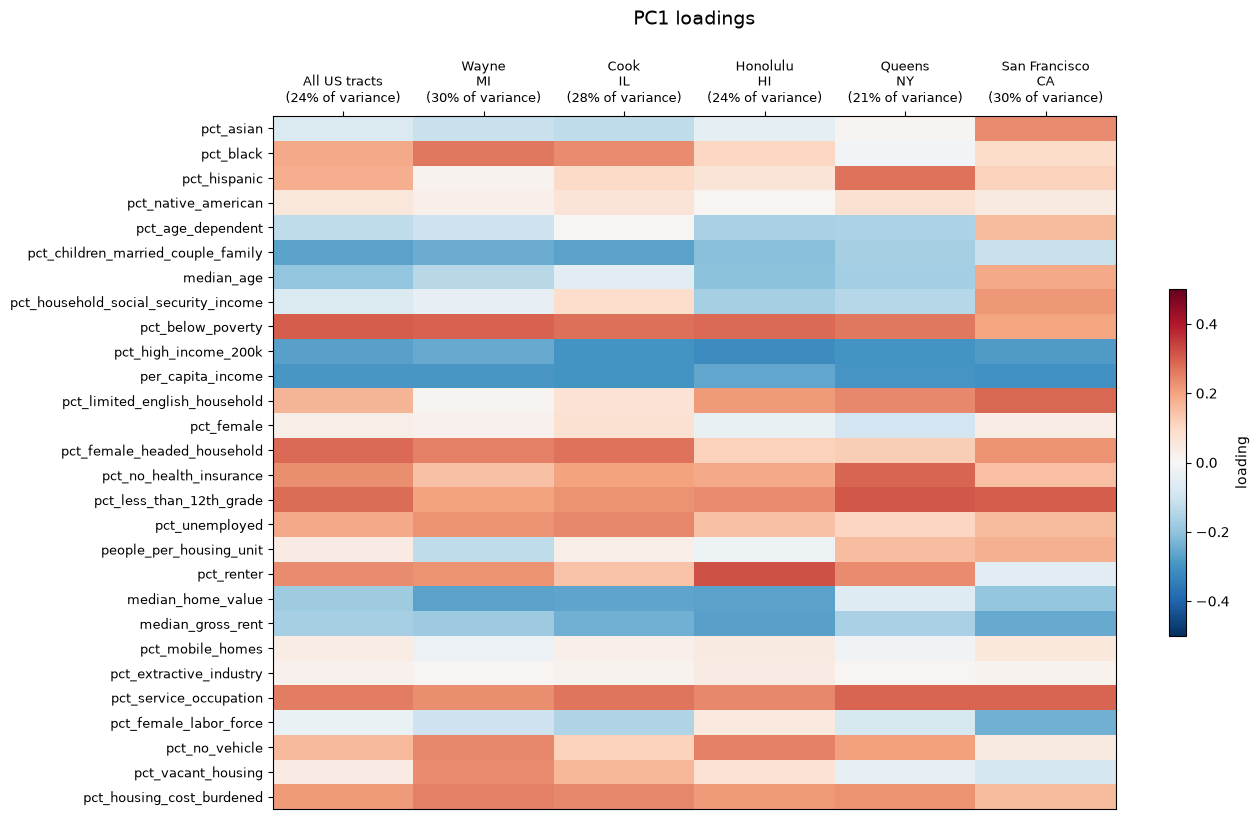

In [4]:
plot_loadings(county_fits, pc=0)

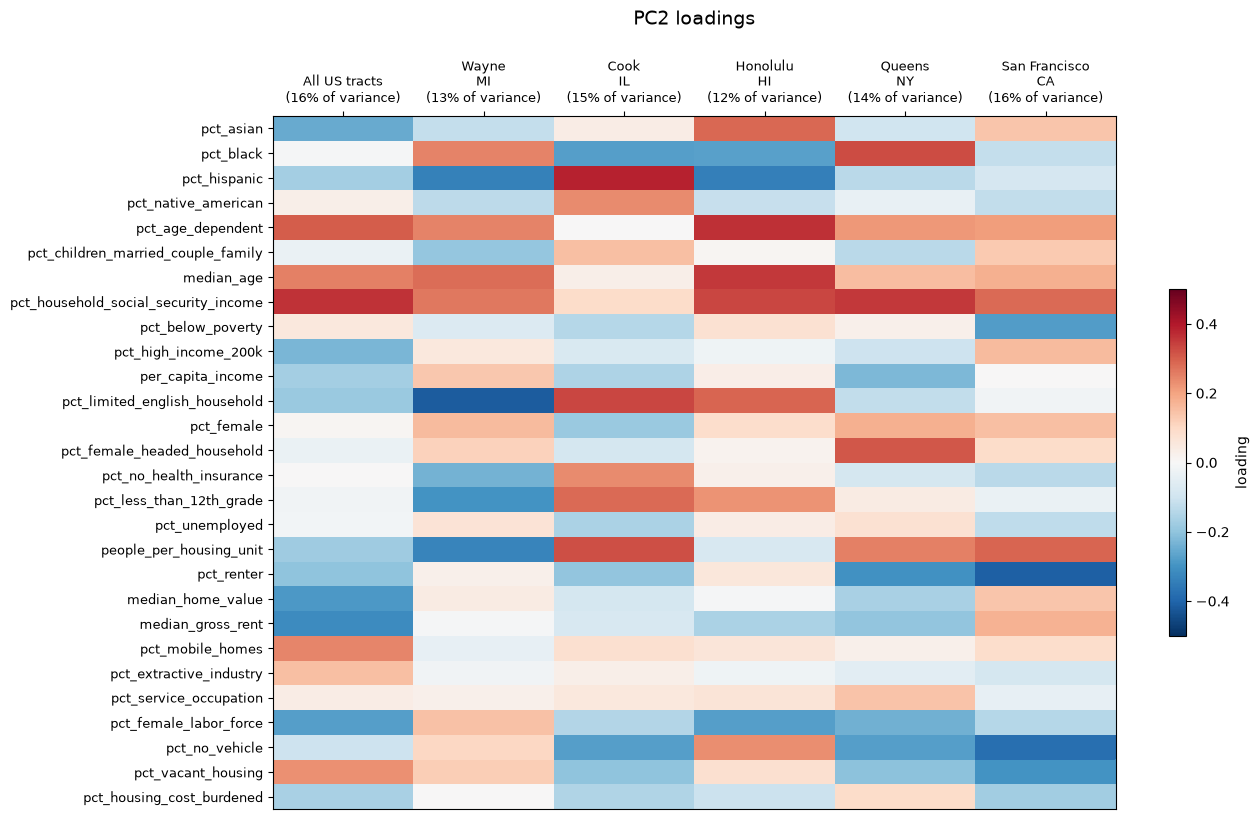

In [5]:
plot_loadings(county_fits, pc=1)

In [6]:
for name, pca in county_fits.items():
    print(name)
    for i, s in enumerate(top_loadings(pca.components_)):
        print(f"   PC{i+1} ({pca.explained_variance_ratio_[i]:.0%}): {s}")

All US tracts
   PC1 (24%): pct_below_poverty (+0.30), per_capita_income (-0.29), pct_female_headed_household (+0.28), pct_less_than_12th_grade (+0.28)
   PC2 (16%): pct_household_social_security_income (+0.36), median_gross_rent (-0.31), pct_age_dependent (+0.30), median_home_value (-0.29)
Wayne, MI
   PC1 (30%): pct_below_poverty (+0.30), per_capita_income (-0.29), median_home_value (-0.27), pct_black (+0.26)
   PC2 (13%): pct_limited_english_household (-0.41), pct_hispanic (-0.34), people_per_housing_unit (-0.33), pct_less_than_12th_grade (-0.30)
Cook, IL
   PC1 (28%): per_capita_income (-0.30), pct_high_income_200k (-0.30), pct_below_poverty (+0.27), pct_female_headed_household (+0.27)
   PC2 (15%): pct_hispanic (+0.38), pct_limited_english_household (+0.33), people_per_housing_unit (+0.32), pct_less_than_12th_grade (+0.28)
Honolulu, HI
   PC1 (24%): pct_renter (+0.32), pct_high_income_200k (-0.31), pct_below_poverty (+0.28), median_gross_rent (-0.27)
   PC2 (12%): pct_age_dependen

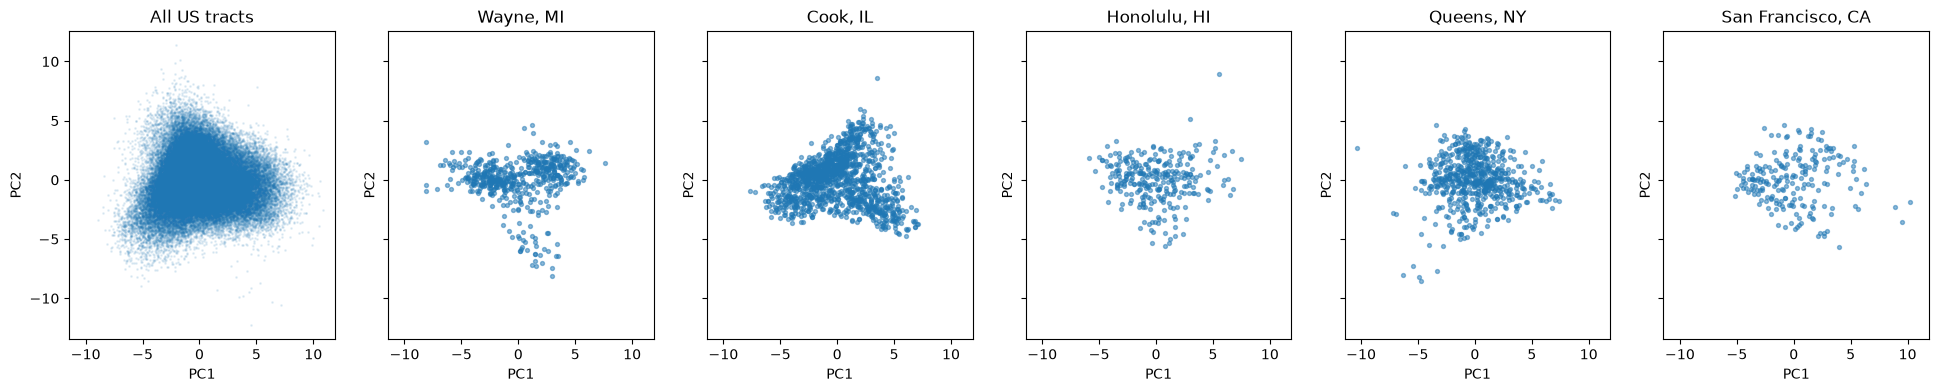

In [7]:
fig, axes = plt.subplots(1, len(county_scores), figsize=(4 * len(county_scores), 4), sharex=True, sharey=True)
for ax, (name, s) in zip(axes, county_scores.items()):
    big = len(s) > 10_000  # shrink and fade markers for the national fit
    ax.scatter(s[:, 0], s[:, 1], s=1 if big else 8, alpha=0.1 if big else 0.5)
    ax.set(title=name, xlabel="PC1", ylabel="PC2")
plt.show()

**Discuss**
- Which counties tell the same story as the national fit? As Wayne? Which tell a different one? Can you give each county's PC1 and PC2 a name (e.g. "wealth", "age", "immigration")?
- The scatter plots show the tracts' scores on each county's own PC1 and PC2. Why can't we simply overlay them and compare the shapes?

## Part 2: Comparing PCs between counties

Now compare each PC directly. In each panel, a point is one SoVI variable; its position is its loading on that PC in county A (x) and county B (y). Points near the dotted diagonal mean the two counties agree about what the variable contributes; points far from it are variables that play a different role in the two counties.

> **Predict:** Which PC will agree more across counties, PC1 or PC2? Which pair of counties will agree the most?

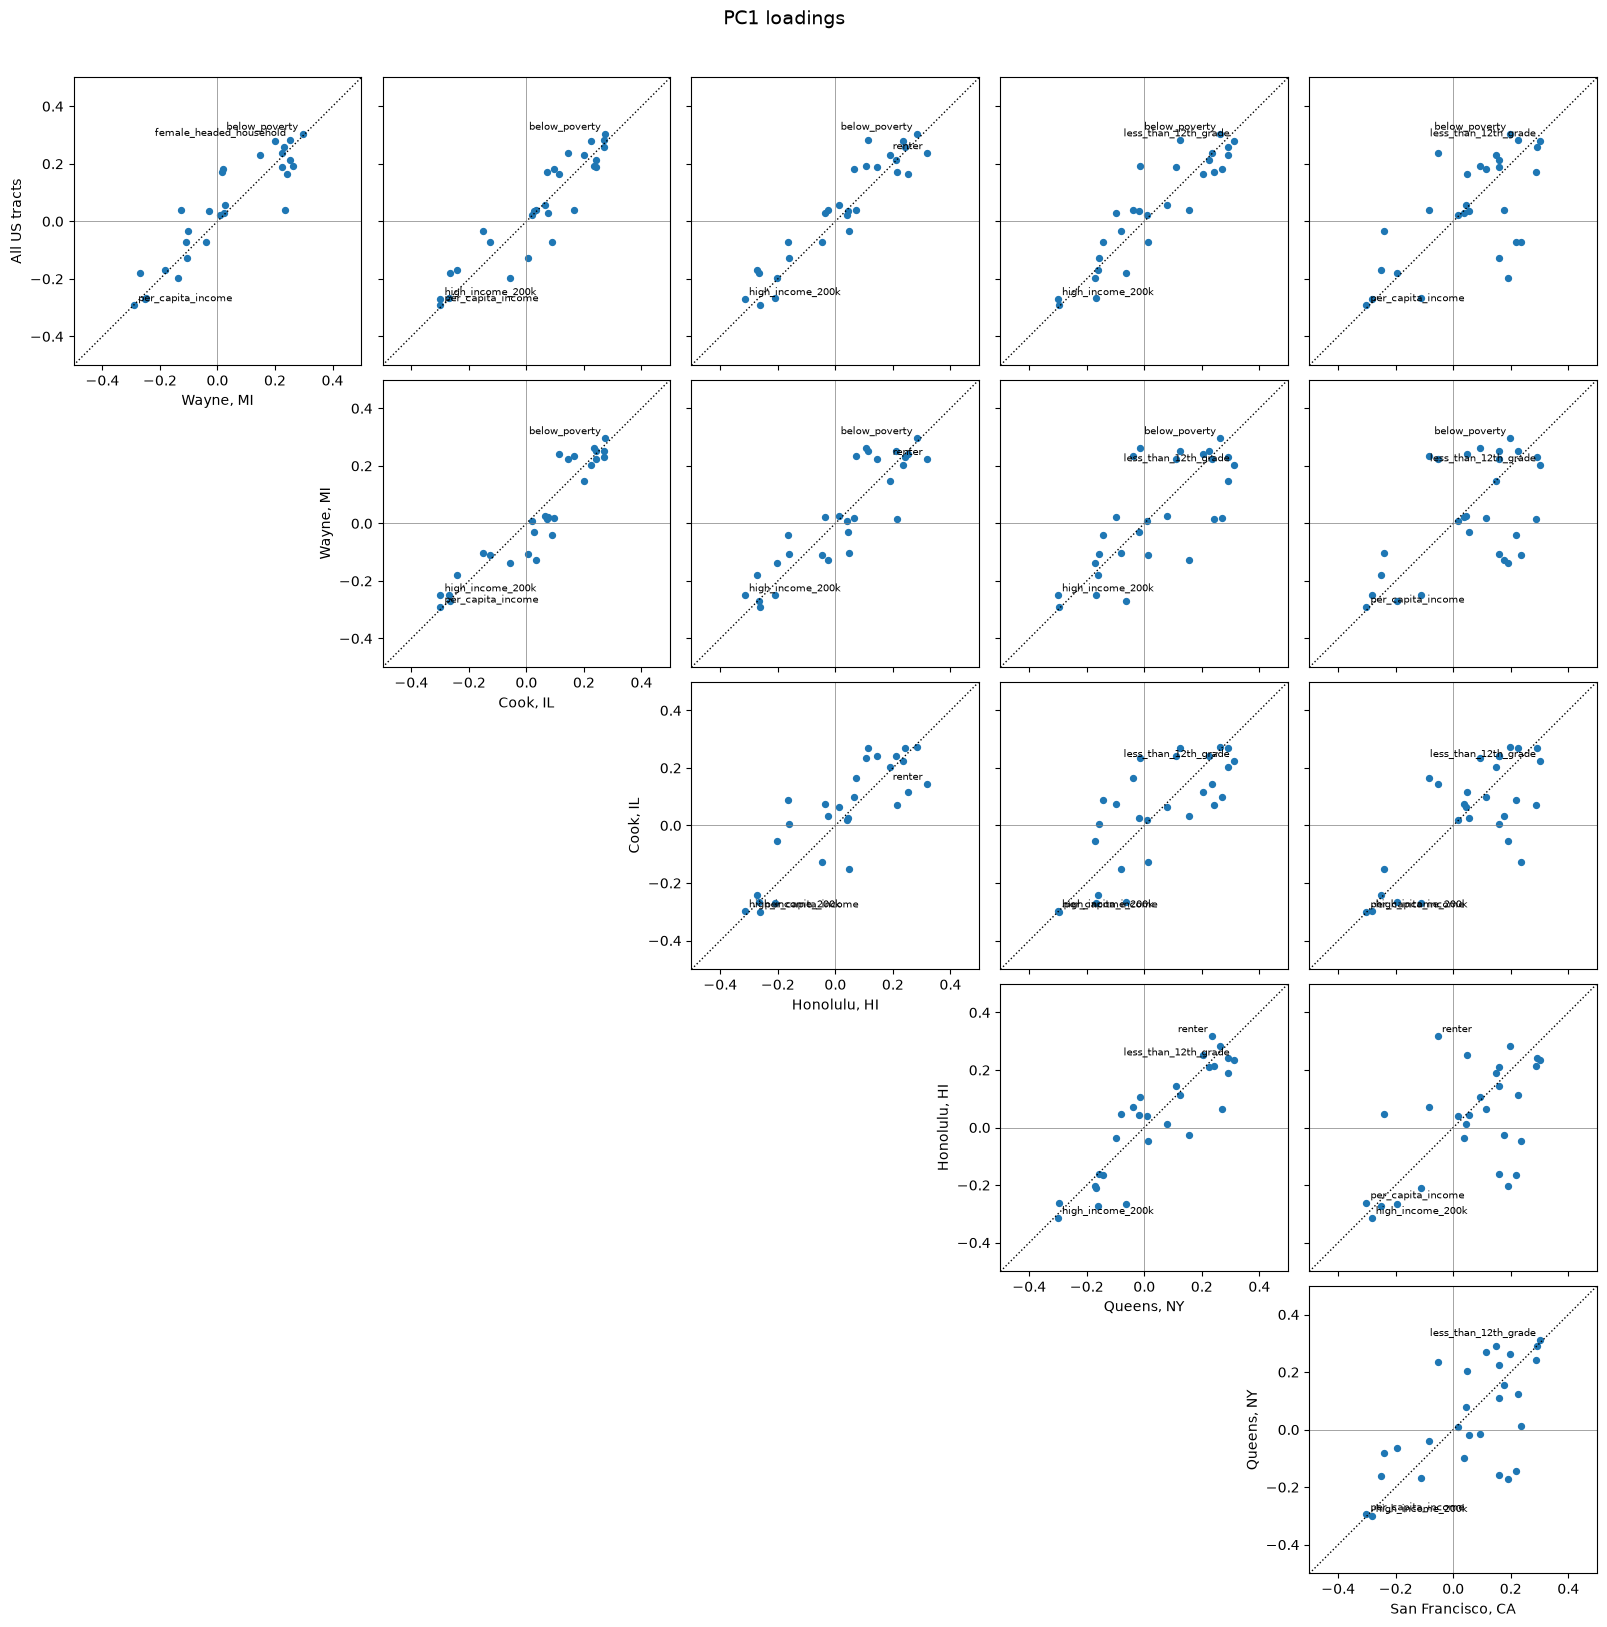

In [8]:
plot_all_pc_scatters(county_fits, pc=0)

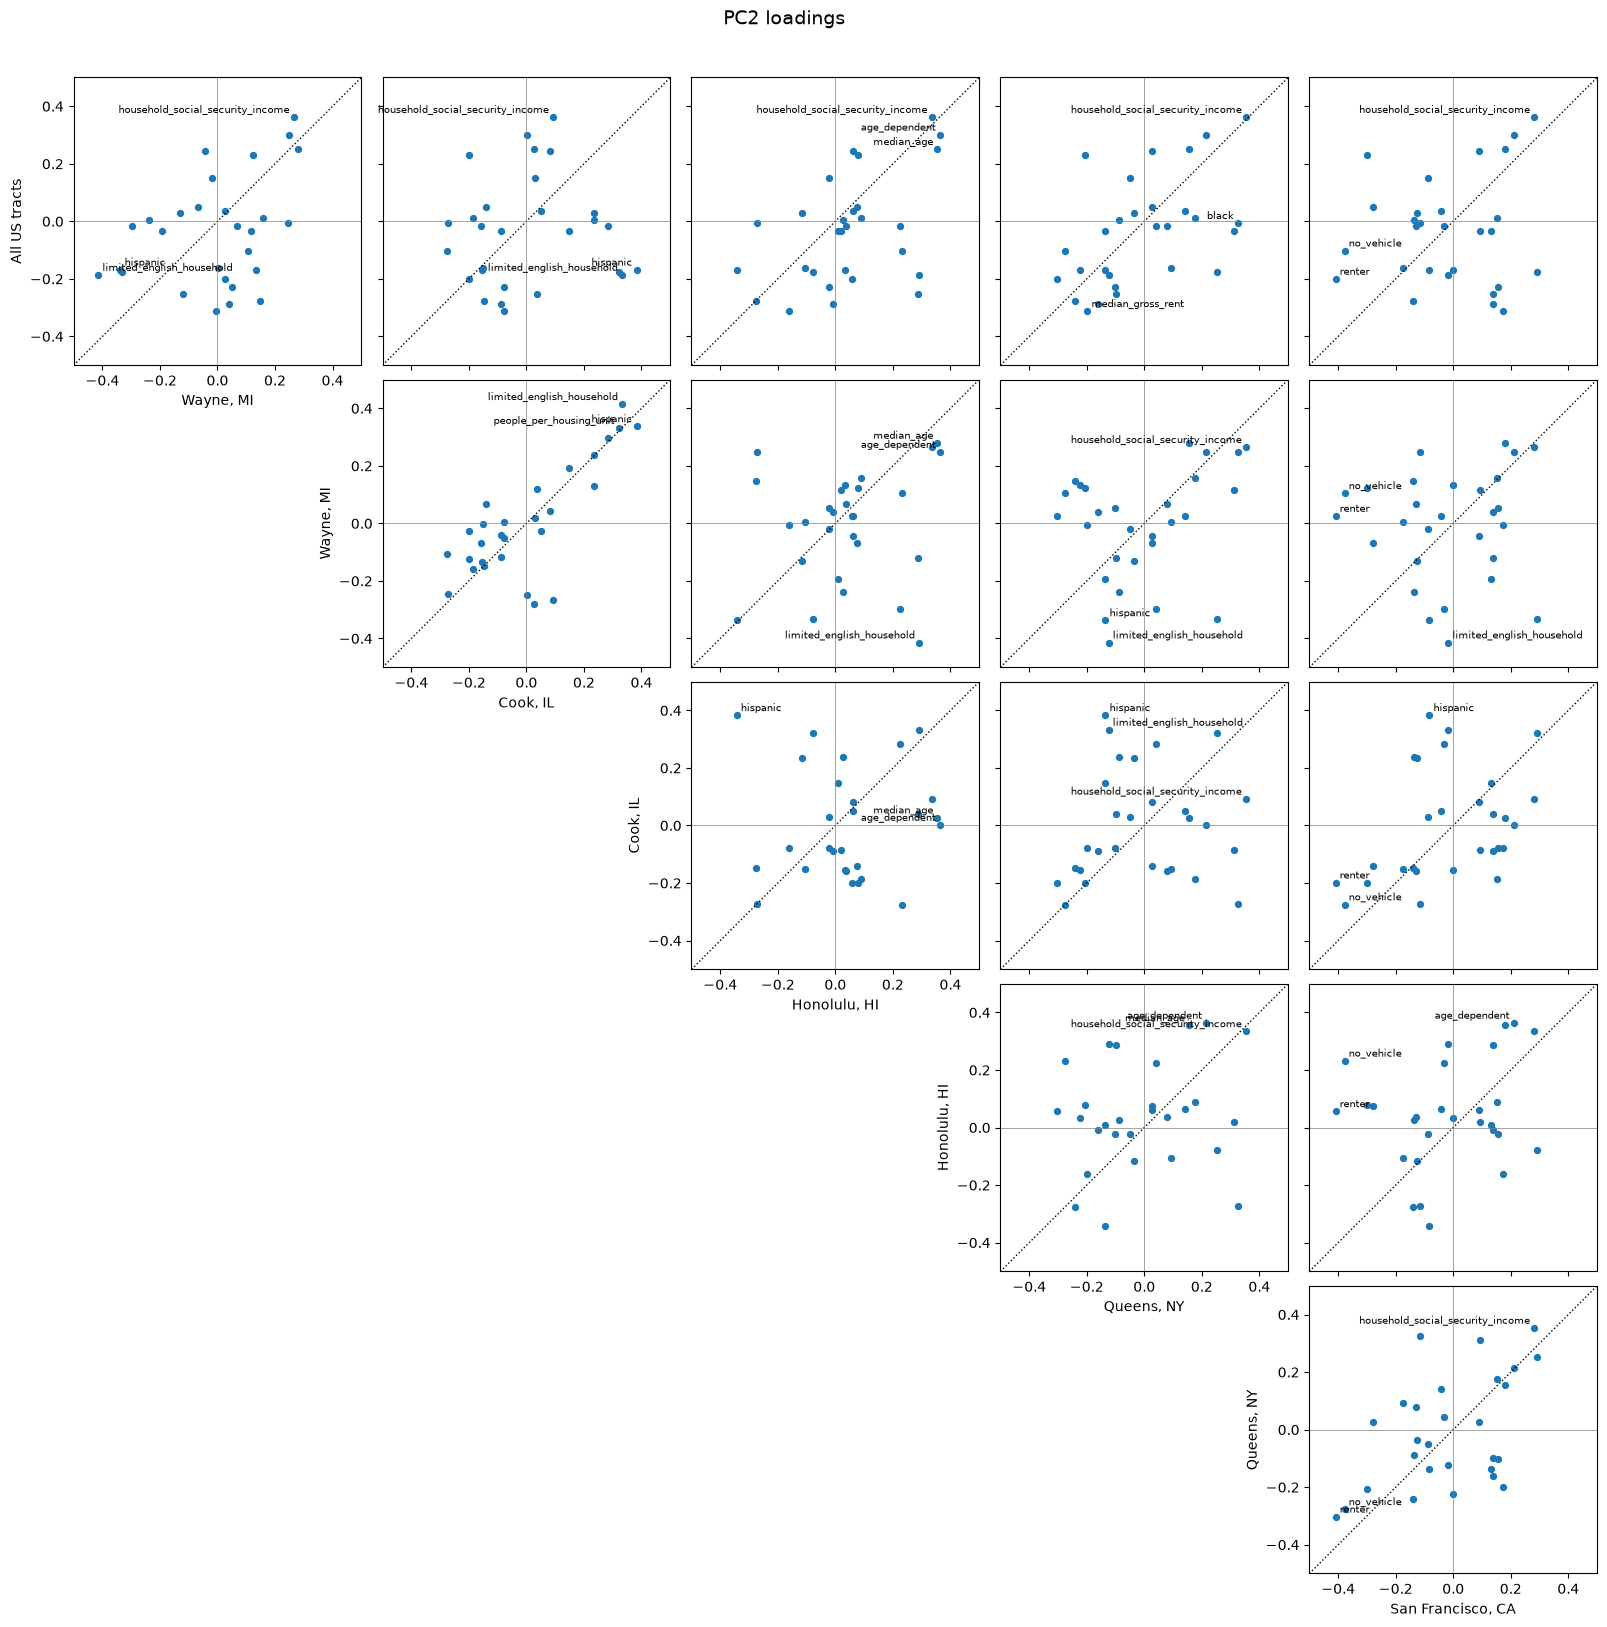

In [9]:
plot_all_pc_scatters(county_fits, pc=1)

**Discuss**
- PC1 is a broadly similar socioeconomic axis in most counties, but PC2 is where counties diverge. Why would the second-largest source of variation be more place-specific than the largest?
- Pick one panel where the points are far from the diagonal. Which variables are responsible? What does that tell you about those two places?
- San Francisco is the least like Wayne on *both* PCs. What about San Francisco's tracts might cause that?

In [10]:
def similarity(fits, pc):
    """|cosine similarity| between the given PC (0 or 1) of every pair of fits. 1 = same direction, 0 = unrelated."""
    names = list(fits)
    M = np.array([fits[n].components_[pc] for n in names])
    return pd.DataFrame(np.abs(M @ M.T), index=names, columns=names).round(2)

for pc in range(2):
    print(f"|cosine similarity| of PC{pc+1} loadings between counties (1 = identical direction)")
    print(similarity(county_fits, pc), "\n")

|cosine similarity| of PC1 loadings between counties (1 = identical direction)
                   All US tracts  Wayne, MI  Cook, IL  Honolulu, HI  \
All US tracts               1.00       0.91      0.92          0.94   
Wayne, MI                   0.91       1.00      0.94          0.89   
Cook, IL                    0.92       0.94      1.00          0.84   
Honolulu, HI                0.94       0.89      0.84          1.00   
Queens, NY                  0.91       0.74      0.77          0.89   
San Francisco, CA           0.66       0.56      0.75          0.56   

                   Queens, NY  San Francisco, CA  
All US tracts            0.91               0.66  
Wayne, MI                0.74               0.56  
Cook, IL                 0.77               0.75  
Honolulu, HI             0.89               0.56  
Queens, NY               1.00               0.66  
San Francisco, CA        0.66               1.00   

|cosine similarity| of PC2 loadings between counties (1 = identi

## Part 3: Does the ordering of tracts change?

The loadings differ, so the *scores* (each tract's position along a PC) must differ too. Here we take the tracts in each county and score them two ways: with the **national** PCA, and with the PCA fit on **only that county**. Both are sign-aligned, so a tract that scores high in one should score high in the other if the two PCAs agree.

Each panel reports the Spearman rank correlation (1 = identical ordering of tracts) and the average change in a tract's within-county percentile rank.

> **Predict:** If you ranked the tracts in your county by PC1, would the national and county PCAs give nearly the same ranking?

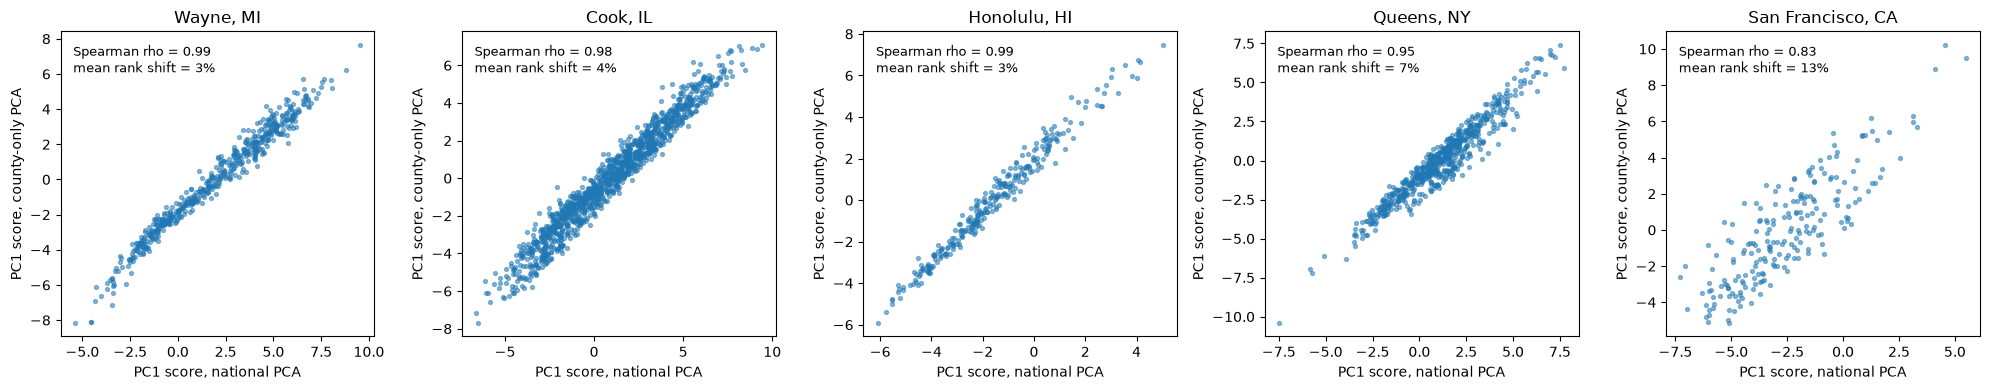

In [11]:
def plot_national_vs_county_scores(pc):
    """For each county, scatter PC `pc` scores from the national PCA (x) vs. the county-only PCA (y)."""
    nat_scores = county_scores[NATIONAL]
    fig, axes = plt.subplots(1, len(COUNTIES), figsize=(4 * len(COUNTIES), 4))
    for ax, (name, fips) in zip(axes, COUNTIES.items()):
        in_county = (tract.GEOID.str[:5] == fips).to_numpy()
        x = pd.Series(nat_scores[in_county, pc])
        y = pd.Series(county_scores[name][:, pc])
        assert len(x) == len(y)
        rho = x.corr(y, method="spearman")
        shift = (x.rank(pct=True) - y.rank(pct=True)).abs().mean()
        ax.scatter(x, y, s=8, alpha=0.5)
        ax.set(title=name, xlabel=f"PC{pc+1} score, national PCA", ylabel=f"PC{pc+1} score, county-only PCA")
        ax.text(0.04, 0.96, f"Spearman rho = {rho:.2f}\nmean rank shift = {shift:.0%}", transform=ax.transAxes,
                va="top", fontsize=9)
    fig.tight_layout()
    plt.show()

plot_national_vs_county_scores(pc=0)

**Discuss**
- In which counties do the two PCAs rank tracts most similarly? Least similarly? Relate this to the loadings similarity from Part 2.
- A tract's rank shift is the change in its percentile within its county. If a program funded the "most vulnerable 10%" of tracts in a county by PC1, how many tracts might change depending on which PCA you used?

## Part 4: What if we use the wrong county's PCA?

A PCA fit is a rotation of the data. We can apply Wayne's rotation to Queens' tracts, but how much of Queens' variation does it capture?

For each pair, we standardize one county's tracts and ask: what fraction of their total variance lies along the *other* county's first two PCs? The diagonal is each county using its own PCs, which is the best possible for two PCs.

In [12]:
def captured(df, pca):
    """Fraction of df's (own-standardized) variance lying in the span of pca's two PCs."""
    Z = StandardScaler().fit_transform(df[SOVI])
    return ((Z @ pca.components_.T) ** 2).sum() / (Z ** 2).sum()

cap = pd.DataFrame(
    {fit_name: {data_name: captured(df, pca) for data_name, df in county_tracts.items()}
     for fit_name, pca in county_fits.items()}
)
cap.index.name, cap.columns.name = "tracts being described", "PCA fit on"
assert np.allclose(np.diag(cap.values), [p.explained_variance_ratio_.sum() for p in county_fits.values()])
print("Share of variance captured by two PCs")
cap.round(2)

Share of variance captured by two PCs


PCA fit on,All US tracts,"Wayne, MI","Cook, IL","Honolulu, HI","Queens, NY","San Francisco, CA"
tracts being described,,,,,,
All US tracts,0.39,0.31,0.30,0.28,0.29,0.26
"Wayne, MI",0.34,0.43,0.39,0.31,0.27,0.30
"Cook, IL",0.36,0.39,0.43,0.29,0.34,0.34
"Honolulu, HI",0.27,0.26,0.23,0.36,0.25,0.30
"Queens, NY",0.26,0.25,0.23,0.25,0.34,0.27
"San Francisco, CA",0.25,0.23,0.31,0.32,0.33,0.45


**Discuss**
- Compare each row's diagonal entry to the other entries in that row. Where are the biggest drops? Which county's PCs travel best to other counties, and which travel worst?
- A state agency fits PCA on its largest county and applies the resulting index everywhere in the state. What could go wrong?

## Part 5: Rotating the components

The first *K* PCs define a *K*-dimensional subspace of the 28-dimensional space of variables. PCA picks one particular set of axes in that subspace (the ones that successively capture the most variance), but any other set of axes in the same subspace captures exactly the same total variance. A **rotation** picks different axes, chosen to make the loadings easier to interpret: ideally each variable loads strongly on one axis and near zero on the others ("simple structure").

- **Varimax** is an *orthogonal* rotation: the new axes stay perpendicular, so the factors are uncorrelated.
- **Oblimin** is an *oblique* rotation: the axes are allowed to tilt toward each other, so the factors can be correlated. That is often more realistic for social data, where "wealth" and "education" are unlikely to be independent.

Rotation needs more than two components to have much room to work, so here we keep **K = 4** and rotate. We use `rotate_factors` from `statsmodels`; scikit-learn only offers varimax inside `FactorAnalysis`, and has no oblimin.

In [13]:
def rotated_fits(pca, Z):
    """Unrotated and varimax / oblimin versions of pca (fit on standardized data Z): {label: (loadings, factor correlations, scores)}."""
    L = pca.components_.T * np.sqrt(pca.explained_variance_)  # variables x components
    S = pca.transform(Z) / np.sqrt(pca.explained_variance_)  # unit-variance PC scores
    out = {"Unrotated PCA": (L, np.eye(L.shape[1]), S)}
    for name, args in [("Varimax", ("varimax",)), ("Oblimin", ("oblimin", 0, "oblique"))]:
        Lr, T = rotate_factors(L, *args)
        Phi = T.T @ T  # correlations between factors (identity for an orthogonal rotation)
        _, order = linear_sum_assignment(-np.abs(L.T @ Lr))  # match each factor to its closest unrotated PC...
        Lr, Phi, F = Lr[:, order], Phi[np.ix_(order, order)], (S @ T)[:, order]  # rotated scores are S @ T
        sign = np.sign(np.diag(L.T @ Lr))  # ...and in sign, since the sign of a factor is arbitrary
        assert np.allclose((F * sign) @ (Lr * sign).T, S @ L.T)  # same fitted data as the unrotated PCs
        out[name] = (Lr * sign, Phi * np.outer(sign, sign), F * sign)
    return out


def plot_rotations(rotated, title, vmax=1):
    """One loadings heatmap with columns grouped by factor: each factor's unrotated/varimax/oblimin loadings side by side."""
    methods, k = list(rotated), next(iter(rotated.values()))[0].shape[1]
    M = np.column_stack([rotated[m][0][:, f] for f in range(k) for m in methods])
    fig, ax = plt.subplots(figsize=(0.9 * M.shape[1] + 4, 9))
    im = ax.imshow(M, cmap="RdBu_r", vmin=-vmax, vmax=vmax, aspect="auto")
    ax.set_xticks(range(M.shape[1]), methods * k, rotation=90, fontsize=8)
    ax.set_yticks(range(len(SOVI)), SOVI, fontsize=9)
    ax.xaxis.tick_top()
    for f in range(k):
        ax.text((f + 0.5) * len(methods) - 0.5, 1.13, f"Factor {f+1}", ha="center", weight="bold", transform=ax.get_xaxis_transform())
        if f > 0:
            ax.axvline(f * len(methods) - 0.5, color="black", lw=2)
    fig.suptitle(title, fontsize=14, y=1.02)
    fig.colorbar(im, ax=ax, label="loading", shrink=0.5)
    plt.show()

In [14]:
ROTATE, K = "Wayne, MI", 4  # ROTATE can be any key of county_fits
Z = StandardScaler().fit_transform(county_tracts[ROTATE][SOVI])
pca_k = PCA(n_components=K).fit(Z)
rotated = rotated_fits(pca_k, Z)

# An orthogonal rotation redistributes variance among the K axes but keeps the total
assert np.isclose((rotated["Varimax"][0] ** 2).sum(), (rotated["Unrotated PCA"][0] ** 2).sum())
print(f"Total variance in {K} components: {(rotated['Unrotated PCA'][0] ** 2).sum() / len(SOVI):.0%}")
for name in ("Unrotated PCA", "Varimax"):
    print(f"{name}: share of variance by factor = {np.round((rotated[name][0] ** 2).sum(axis=0) / len(SOVI), 2)}")
offdiag = rotated["Oblimin"][1] - np.eye(K)
print(f"Oblimin: largest correlation between two factors = {np.abs(offdiag).max():.2f}")

for name, (L, _, _) in rotated.items():
    A = np.sort(np.abs(L), axis=1)[:, ::-1]
    n_clear = (A[:, 1] < 0.5 * A[:, 0]).sum()  # second-largest loading less than half the largest
    print(f"\n{name}: {n_clear} of {len(SOVI)} variables load mostly on one factor")
    for i, s in enumerate(top_loadings(L.T)):
        print(f"   Factor {i+1}: {s}")

Total variance in 4 components: 57%
Unrotated PCA: share of variance by factor = [0.3  0.13 0.08 0.06]
Varimax: share of variance by factor = [0.22 0.11 0.1  0.14]
Oblimin: largest correlation between two factors = 0.44

Unrotated PCA: 13 of 28 variables load mostly on one factor
   Factor 1: pct_below_poverty (+0.86), per_capita_income (-0.85), median_home_value (-0.79), pct_black (+0.77)
   Factor 2: pct_limited_english_household (+0.79), pct_hispanic (+0.64), people_per_housing_unit (+0.63), pct_less_than_12th_grade (+0.56)
   Factor 3: pct_household_social_security_income (+0.66), pct_female_labor_force (-0.64), pct_age_dependent (+0.63), median_age (+0.55)
   Factor 4: pct_asian (+0.55), median_home_value (+0.41), pct_no_vehicle (+0.40), pct_renter (+0.38)

Varimax: 15 of 28 variables load mostly on one factor
   Factor 1: pct_no_vehicle (+0.81), pct_black (+0.80), pct_vacant_housing (+0.73), pct_below_poverty (+0.72)
   Factor 2: pct_limited_english_household (+0.81), pct_less_th

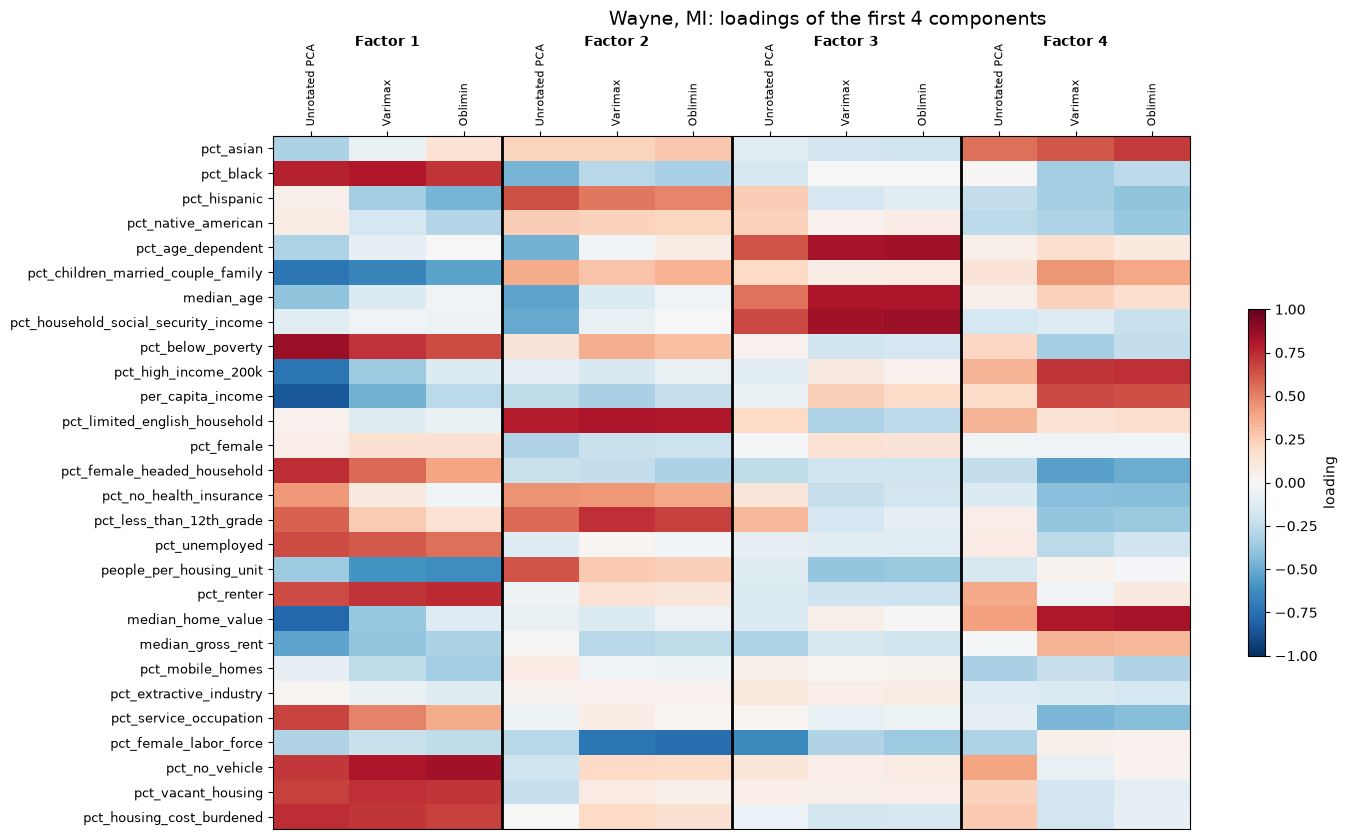

In [15]:
plot_rotations(rotated, title=f"{ROTATE}: loadings of the first {K} components")

The rotated factors also give each tract a new set of scores. The top row plots the tracts on Factor 1 vs. Factor 2 under each method (the unrotated panel is the PC1 vs. PC2 plot, rescaled to unit variance). The bottom row shows the pair of factors that oblimin allows to be most correlated.

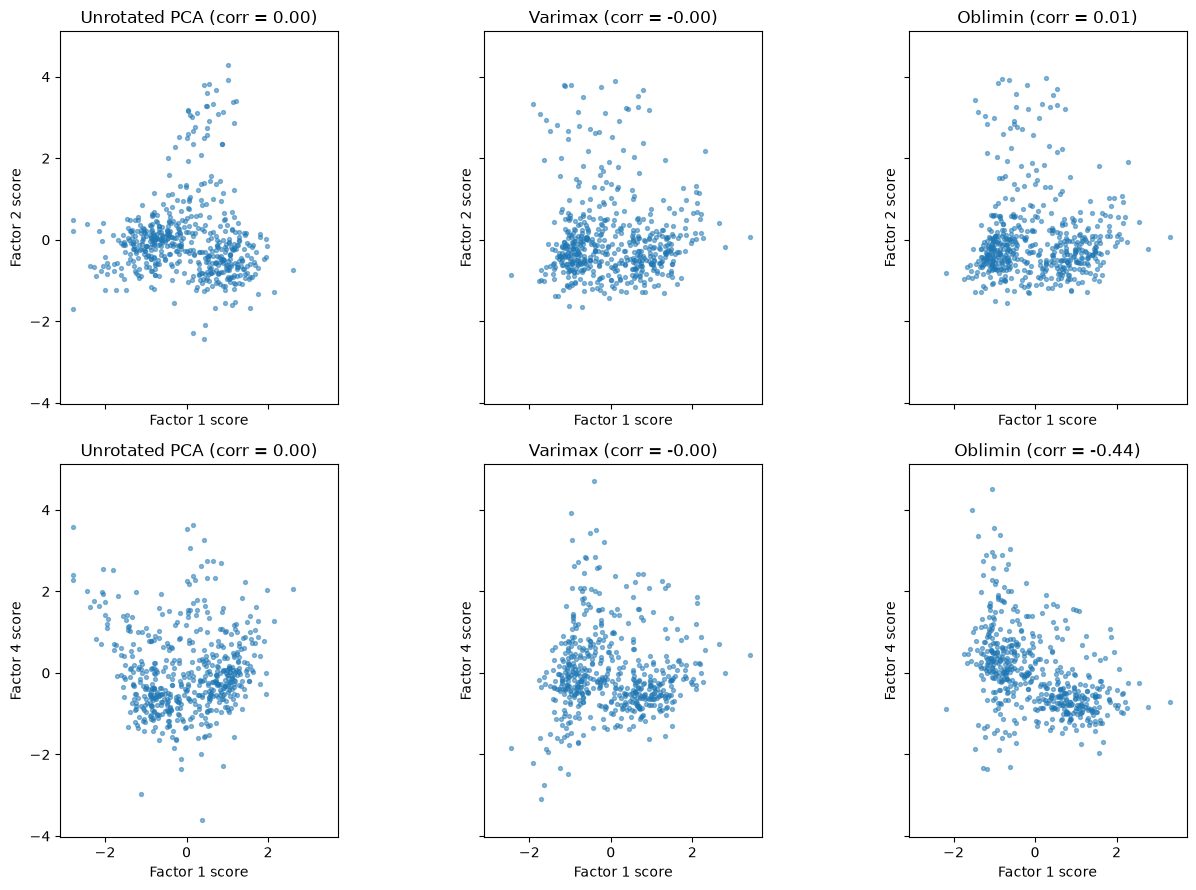

In [16]:
off = np.abs(rotated["Oblimin"][1] - np.eye(K))
pairs = [(0, 1), tuple(int(i) for i in np.unravel_index(off.argmax(), off.shape))]  # Factors 1 vs 2, and the oblimin pair that is most correlated
fig, axes = plt.subplots(len(pairs), len(rotated), figsize=(4.5 * len(rotated), 4.5 * len(pairs)), sharex=True, sharey=True)
for row, (i, j) in zip(axes, pairs):
    for ax, (name, (_, _, F)) in zip(row, rotated.items()):
        ax.scatter(F[:, i], F[:, j], s=8, alpha=0.5)
        ax.set(title=f"{name} (corr = {np.corrcoef(F[:, i], F[:, j])[0, 1]:.2f})",
               xlabel=f"Factor {i+1} score", ylabel=f"Factor {j+1} score", aspect="equal")
fig.tight_layout()
plt.show()

**Discuss**
- Within each factor, compare the unrotated, varimax and oblimin columns. Can you give each varimax factor a name? Is that easier or harder than naming the unrotated PCs?
- The rotated axes span the same 4-dimensional subspace, so they carry exactly the same information as the first four PCs. What did we change, then, and who benefits from the change?
- Compare the scatter plots across the three methods. How does the shape of the point cloud change? Unrotated PCs and varimax factors are uncorrelated by construction; in the bottom row, only the oblimin panel is allowed a tilted cloud.
- Oblimin lets the factors correlate. Which factors are correlated, and does that match your intuition about the county?
- Rotation does not remove the dependence on the data. Change `ROTATE` to another fit (for example `"San Francisco, CA"` or `NATIONAL`) and re-run: do the same factors appear?
- Try `K = 2` and `K = 6`. How does the benefit of rotating change with the number of components kept?

## Takeaways

- PCA summarizes the **covariance structure of the rows you gave it**. A different set of rows (here, a different county, or the whole country) means different covariances, so different loadings, different variance explained, and sometimes a different ordering of components.
- "PC1" is not a fixed quantity. Before comparing or reusing components, ask: *fit on which data?*
- Fitting on a large geography and applying elsewhere (or fitting locally and generalizing) is a modeling choice, with consequences for how well the components describe the data you actually care about.
- Rotations (varimax, oblimin) re-express the same components to be easier to interpret; they are a choice about presentation, and they inherit the dependence on the data.
- **For your own work:** when you report a PCA, state what data it was fit on, and be careful about applying it to data it wasn't fit on.